In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import RemappingModel
from scipy.stats import binned_statistic_2d

import utils

In [2]:
# Load model parameters
sigma_A = torch.load("./parameters/sigma_A_pc.pt", weights_only=True)
sigma_B = torch.load("./parameters/sigma_B_pc.pt", weights_only=True)
sigma_C = torch.load("./parameters/sigma_C_pc.pt",  weights_only=True)

R = utils.random_orthogonal_matrix(len(sigma_A))

p0 = utils.starting_state(R)
p0 = p0.to(torch.float32)

A = R.T@sigma_A@R 
B = R.T@sigma_B@R
C = R.T@sigma_C@R

model = RemappingModel(A, B, C)
print(f"Number of units: {len(A)}")

Number of units: 300


In [3]:
batch_size = 50 # number of spatial samples
batches = 500
arena_size = 3
r_batch = [arena_size*(2*torch.rand((batch_size, 2)).to(torch.float32) - 1) for i in range(batches)] # spatial dataset
r = np.concatenate(r_batch) 

In [4]:
c1 = torch.tensor(0.0)
c2 = torch.tensor(5.0)
rc1 = [torch.cat((ri, c1*torch.ones((batch_size,1), dtype = torch.float32)), dim=1) for ri in r_batch]
rc2 = [torch.cat((ri, c2*torch.ones((batch_size,1), dtype = torch.float32)), dim=1) for ri in r_batch]

# run model
p1 = utils.batch_inference(model, rc1, p0)
p2 = utils.batch_inference(model, rc2, p0)


100%|██████████| 500/500 [01:17<00:00,  6.48it/s]


(<Figure size 200x200 with 25 Axes>,
 array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object))

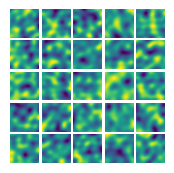

In [5]:
ratemaps1 = utils.compute_ratemaps(r[:,0], r[:,1], p1, bins = 32)
utils.ratemap_collage(ratemaps1, 5, 5, figsize = (2,2))

(<Figure size 200x200 with 25 Axes>,
 array([[<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >]], dtype=object))

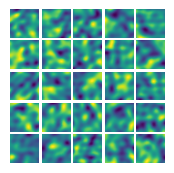

In [6]:
ratemaps2 = utils.compute_ratemaps(r[:,0], r[:,1], p2, bins = 32)
utils.ratemap_collage(ratemaps2, 5, 5, figsize = (2,2))

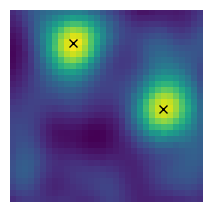

In [64]:
# Random locations for "reward"
pRS = ratemaps1[:,25, 16] + ratemaps1[:,10,5] + ratemaps2[:,-25, -5]
C_rs1 = np.nansum(pRS[:, None,None]*ratemaps1, axis = 0)
plt.figure(figsize=(2.5,2.5))
plt.imshow(C_rs1.T)
plt.plot(25, 16, 'kx')
plt.plot(10, 5, 'kx')
plt.axis('off')
plt.savefig("./figures/pc_rewarded_ratemap1.svg", dpi = 300, bbox_inches = "tight")

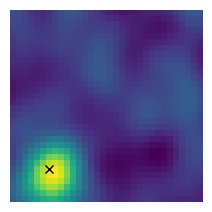

In [65]:
C_rs2 = np.nansum(pRS[:, None,None]*ratemaps2, axis = 0)
plt.figure(figsize=(2.5,2.5))
plt.imshow(C_rs2.T)
plt.plot(6, 32-6, 'kx')

plt.axis('off')
plt.savefig("./figures/pc_rewarded_ratemap2.svg", dpi = 300, bbox_inches = "tight")

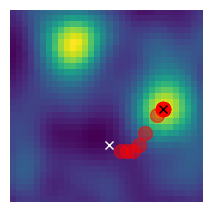

In [63]:
plt.figure(figsize=(2.5,2.5))

ind = np.array([16, 22])
eta = 75

for i in range(20):

    x, y = ind

    # current objective
    C = np.nansum(pRS * ratemaps1[:, x, y])

    # finite difference gradient
    # use clipped neighbors to avoid OOB
    C_xp = np.sum(pRS * ratemaps1[:, min(x+1, 32-1), y])
    C_xm = np.sum(pRS * ratemaps1[:, max(x-1, 0), y])
    C_yp = np.sum(pRS * ratemaps1[:, x, min(y+1, 32-1)])
    C_ym = np.sum(pRS * ratemaps1[:, x, max(y-1, 0)])

    Dx = (C_xp - C_xm) / 2
    Dy = (C_yp - C_ym) / 2

    # small learning rate so you move 1 cell at a time
    ind = ind + (eta*0.8**(i) * np.array([Dx, Dy])).astype(int)

    # bounds
    ind[0] = np.clip(ind[0], 0, 32-1)
    ind[1] = np.clip(ind[1], 0, 32-1)

    plt.plot(ind[0], ind[1], "or", alpha = 0.5 , markersize = 10)

plt.imshow(C_rs1.T)
plt.plot(16, 22, 'wx')
plt.plot(25, 16, 'kx')
# plt.axis([-2, 34, -2, 34])
plt.axis('off')
plt.savefig("./figures/reward_gradient_navigation.svg", dpi = 300, bbox_inches = "tight")

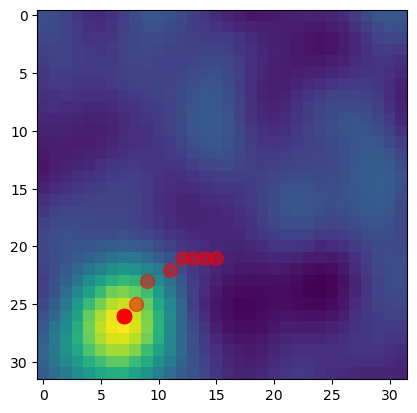

In [48]:
ind = np.array([16, 22])
eta = 60

for i in range(20):

    x, y = ind

    # current objective
    C = np.nansum(pRS * ratemaps2[:, x, y])

    # finite difference gradient
    # use clipped neighbors to avoid OOB
    C_xp = np.sum(pRS * ratemaps2[:, min(x+1, 32-1), y])
    C_xm = np.sum(pRS * ratemaps2[:, max(x-1, 0), y])
    C_yp = np.sum(pRS * ratemaps2[:, x, min(y+1, 32-1)])
    C_ym = np.sum(pRS * ratemaps2[:, x, max(y-1, 0)])

    Dx = (C_xp - C_xm) / 2
    Dy = (C_yp - C_ym) / 2

    # small learning rate so you move 1 cell at a time
    ind = ind + (eta*0.8**(i) * np.array([Dx, Dy])).astype(int)

    # bounds
    ind[0] = np.clip(ind[0], 0, 32-1)
    ind[1] = np.clip(ind[1], 0, 32-1)

    plt.plot(ind[0], ind[1], "or", alpha = 0.5 , markersize = 10)

plt.imshow(C_rs2.T)
# plt.axis([-2, 34, -2, 34])
